# RGB–열화상 4채널 YOLO11-seg: 건물 외벽 결함 (BFDD)

강교량 도장 손상 논문(Engineering Structures, 2026)을 읽고 시작한 실험이다. 논문은 RGB에 능동 열화상을 붙여 4채널로 YOLO에 넣었고, RGB / IR / CbCr+IR / RGB+IR 네 가지 입력을 비교했다. 같은 비교를 직접 해 보고 싶었다.

도장 손상 RGB–IR 공개 데이터는 찾지 못했다. 대신 건물 외벽 결함(균열, 박리, 들뜸, 얼룩, 침식)을 RGB와 IR 짝으로 찍고 픽셀 마스크까지 단 BFDD를 찾아서 이걸로 했다. 들뜸이 논문의 내부 들뜸과 비슷한 손상이라 IR 효과를 보기 좋다고 생각했다.

논문을 읽으면서 걸렸던 부분은 바꿔서 했다.

- 검증 데이터는 촬영 세션 단위로 나눴다. 비슷한 프레임이 학습과 검증에 같이 들어가는 걸 막으려고.
- HSV 색 증강은 다 껐다. 4채널에는 적용이 안 돼서, RGB에만 켜면 비교가 불공평해진다.
- 재현율과 클래스별 성능도 같이 봤다. 논문에는 재현율이 없었다.
- 박스 면적이 실제 손상 면적보다 얼마나 큰지도 따로 계산했다.

실행: 런타임을 T4 GPU로 바꾸고 전체 실행. 데이터(약 553 MB)는 Mendeley에서 바로 받아 오고, 결과는 Drive의 bfdd_rgbir/에 저장된다.

데이터: BFDD, Mendeley Data, DOI 10.17632/9ych7czvyg.1 (CC BY 4.0)

In [1]:
!nvidia-smi -L
!pip -q install ultralytics
from google.colab import drive
drive.mount('/content/drive')

GPU 0: Tesla T4 (UUID: GPU-e6b81602-e8aa-ae32-876f-d000fcb9888b)
Mounted at /content/drive


In [2]:
from pathlib import Path
WORK     = Path('/content/bfdd')
SAVE_DIR = Path('/content/drive/MyDrive/bfdd_rgbir')
WEIGHTS  = 'yolo11n-seg.pt'      # 여유가 있으면 'yolo11s-seg.pt'
EPOCHS, IMGSZ, BATCH, SEED = 100, 640, 16, 0   # 처음 확인만 하려면 EPOCHS = 5
SAVE_DIR.mkdir(parents=True, exist_ok=True)

In [3]:
%%writefile bfdd_fusion.py
"""RGB-IR input-fusion comparison with YOLO-seg on BFDD (building facade defects).

Dataset: BFDD - A Pixel-Level Aligned RGB-IR Image Dataset for Building Facade Defect
Segmentation (Mendeley Data, DOI 10.17632/9ych7czvyg.1, CC BY 4.0).

Archive layout (v1, file "BFDD Dataset_1x_20260408.tar.gz"):
  Dataset_1x/RGB/<name>.JPG      visible, 640x512
  Dataset_1x/IR/<name>.png       thermal, 640x512, rendered with a rainbow palette
  Dataset_1x/Label/<name>.png    semantic mask, 0=background, 1..5 = defect classes
  Dataset_1x/train.txt, test.txt official split (686 / 152)

Input modes
  rgb     : visible
  ir      : palette-inverted thermal intensity, replicated to 3 channels
  cbcrir  : (Cb, Cr, IR)
  rgbir   : (B, G, R, IR) 4-channel early fusion
"""
from __future__ import annotations

import csv
import datetime as dt
import hashlib
import random
import tarfile
import urllib.request
from pathlib import Path

import cv2
import numpy as np
import torch

URL = ("https://data.mendeley.com/public-files/datasets/9ych7czvyg/files/"
       "c1c5144b-cb20-4687-b514-d0bbec12209e/file_downloaded")
SHA256 = "43d06305bf3c913f59d52c3ffa10caa0e129b668b7b3c9d8f80d619c6e6e8a7a"
MODES = ["rgb", "ir", "cbcrir", "rgbir"]
# Class order as listed on the dataset page (Cracks, Peeling, Hollow Areas, Stains, Erosion).
# The archive itself has no class table; check visually with show_classes() before reporting.
NAMES = {0: "crack", 1: "peeling", 2: "hollow", 3: "stain", 4: "erosion"}


# --------------------------------------------------------------------------- #
# 1. Download / extract
# --------------------------------------------------------------------------- #
def download(dst_dir: Path) -> Path:
    dst_dir = Path(dst_dir)
    dst_dir.mkdir(parents=True, exist_ok=True)
    root = dst_dir / "Dataset_1x"
    if (root / "RGB").exists():
        return root
    tgz = dst_dir / "bfdd.tar.gz"
    if not tgz.exists():
        print("Downloading BFDD (~553 MB) ...")
        req = urllib.request.Request(URL, headers={"User-Agent": "Mozilla/5.0"})
        with urllib.request.urlopen(req) as r, open(tgz, "wb") as f:
            while chunk := r.read(1 << 22):
                f.write(chunk)
    h = hashlib.sha256()
    with open(tgz, "rb") as f:
        while chunk := f.read(1 << 22):
            h.update(chunk)
    if h.hexdigest() != SHA256:
        raise RuntimeError("checksum mismatch - delete bfdd.tar.gz and retry")
    with tarfile.open(tgz) as t:
        t.extractall(dst_dir)
    return root


# --------------------------------------------------------------------------- #
# 2. Thermal palette -> scalar intensity
# --------------------------------------------------------------------------- #
def ir_to_gray(ir_bgr: np.ndarray, hue_cold: float = 141.0) -> np.ndarray:
    """Invert the rainbow palette: red (hue 0) = hot -> 255, purple (hue ~141) = cold -> 0.

    A plain BGR->gray conversion is NOT monotonic for a rainbow palette (yellow is brighter
    than red), so it would scramble the temperature order.
    """
    hue = cv2.cvtColor(ir_bgr, cv2.COLOR_BGR2HSV)[..., 0].astype(np.float32)
    hue[hue > 160] = 0  # wrap-around reds
    return np.clip((1 - hue / hue_cold) * 255, 0, 255).astype(np.uint8)


# --------------------------------------------------------------------------- #
# 3. Split: official test, validation = whole capture sessions taken from train
# --------------------------------------------------------------------------- #
def _time(name: str) -> dt.datetime:
    return dt.datetime.strptime(name.split("_")[1], "%Y%m%d%H%M%S")


def sessions(names, gap_s=120):
    """Group frames into capture sessions (new session when >gap_s seconds between frames)."""
    out, sid, prev = {}, 0, None
    for n in sorted(names, key=_time):
        if prev is not None and (_time(n) - _time(prev)).total_seconds() > gap_s:
            sid += 1
        out[n], prev = sid, n
    return out


def make_split(root: Path, val_frac=0.15, seed=0):
    read = lambda f: [l.strip() for l in open(root / f) if l.strip()]
    train, test = read("train.txt"), read("test.txt")
    ses = sessions(train)
    ids = sorted(set(ses.values()))
    random.Random(seed).shuffle(ids)
    val_ids, acc = set(), 0
    for i in ids:  # take whole sessions until ~val_frac of frames
        if acc >= val_frac * len(train):
            break
        val_ids.add(i)
        acc += sum(1 for v in ses.values() if v == i)
    val = [n for n in train if ses[n] in val_ids]
    tr = [n for n in train if ses[n] not in val_ids]
    return {"train": tr, "val": val, "test": test}


# --------------------------------------------------------------------------- #
# 4. Semantic mask -> YOLO-seg polygons
# --------------------------------------------------------------------------- #
def mask_to_yolo_seg(mask: np.ndarray, min_area=20, eps=1.0):
    h, w = mask.shape
    lines = []
    for k in range(1, 6):
        m = (mask == k).astype(np.uint8)
        if not m.any():
            continue
        cnts, _ = cv2.findContours(m, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
        for c in cnts:
            if cv2.contourArea(c) < min_area:
                continue
            c = cv2.approxPolyDP(c, eps, True).reshape(-1, 2)
            if len(c) < 3:
                continue
            pts = " ".join(f"{x / w:.5f} {y / h:.5f}" for x, y in c)
            lines.append(f"{k - 1} {pts}")
    return lines


def compose(vis_bgr, ir_gray, mode):
    if mode == "rgb":
        return vis_bgr
    if mode == "ir":
        return cv2.merge([ir_gray] * 3)
    if mode == "cbcrir":
        ycrcb = cv2.cvtColor(vis_bgr, cv2.COLOR_BGR2YCrCb)
        return cv2.merge([ir_gray, ycrcb[..., 1], ycrcb[..., 2]])  # model sees (Cb, Cr, IR)
    if mode == "rgbir":
        b, g, r = cv2.split(vis_bgr)
        return cv2.merge([b, g, r, ir_gray])
    raise ValueError(mode)


def build_datasets(root, out_root, split, modes=MODES):
    root, out_root = Path(root), Path(out_root)
    for mode in modes:
        for sp in split:
            (out_root / mode / "images" / sp).mkdir(parents=True, exist_ok=True)
            (out_root / mode / "labels" / sp).mkdir(parents=True, exist_ok=True)
    for sp, names in split.items():
        for n in names:
            vis = cv2.imread(str(root / "RGB" / f"{n}.JPG"), cv2.IMREAD_COLOR)
            ir = ir_to_gray(cv2.imread(str(root / "IR" / f"{n}.png"), cv2.IMREAD_COLOR))
            lab = "\n".join(mask_to_yolo_seg(cv2.imread(str(root / "Label" / f"{n}.png"), cv2.IMREAD_GRAYSCALE)))
            for mode in modes:
                cv2.imwrite(str(out_root / mode / "images" / sp / f"{n}.png"), compose(vis, ir, mode))
                (out_root / mode / "labels" / sp / f"{n}.txt").write_text(lab)
    yamls = {}
    names_yaml = "".join(f"  {k}: {v}\n" for k, v in NAMES.items())
    for mode in modes:
        y = out_root / mode / "data.yaml"
        y.write_text(f"path: {(out_root / mode).as_posix()}\ntrain: images/train\nval: images/val\n"
                     f"test: images/test\nchannels: {4 if mode == 'rgbir' else 3}\nnames:\n{names_yaml}")
        yamls[mode] = y
    return yamls


# --------------------------------------------------------------------------- #
# 5. Trainer: 4-channel first conv initialised from pretrained RGB filters
# --------------------------------------------------------------------------- #
def make_trainer_cls(init="mean"):
    from ultralytics.models.yolo.segment import SegmentationTrainer

    class FusionSegTrainer(SegmentationTrainer):
        def get_model(self, cfg=None, weights=None, verbose=True):
            model = super().get_model(cfg=cfg, weights=weights, verbose=verbose)
            if weights is not None and self.data.get("channels", 3) == 4:
                src = weights.state_dict() if hasattr(weights, "state_dict") else weights
                w3 = src["model.0.conv.weight"].float()
                conv = model.model[0].conv
                if w3.shape[1] == 3 and conv.weight.shape[1] == 4:
                    extra = w3.mean(1, keepdim=True) if init == "mean" else torch.zeros_like(w3[:, :1])
                    with torch.no_grad():
                        conv.weight.copy_(torch.cat([w3[:, [2, 1, 0]], extra], 1).to(conv.weight.dtype))
                    print(f"[FusionSegTrainer] first conv extended to 4 channels (IR init = {init})")
            return model

    return FusionSegTrainer


def run_experiments(yamls, project, weights="yolo11n-seg.pt", epochs=100, imgsz=640, batch=16,
                    seed=0, device=None, modes=MODES, extra_args=None):
    from ultralytics import YOLO

    common = dict(epochs=epochs, imgsz=imgsz, batch=batch, seed=seed, deterministic=True,
                  hsv_h=0.0, hsv_s=0.0, hsv_v=0.0, project=str(project), exist_ok=True, workers=2)
    if device is not None:
        common["device"] = device
    if extra_args:
        common.update(extra_args)
    rows, per_class = [], []
    for mode in modes:
        print(f"\n===== {mode} =====")
        YOLO(weights).train(data=str(yamls[mode]), name=mode, trainer=make_trainer_cls(), **common)
        m = YOLO(str(Path(project) / mode / "weights" / "best.pt")).val(
            data=str(yamls[mode]), split="test", imgsz=imgsz, batch=batch,
            project=str(project), name=f"{mode}_test", exist_ok=True)
        rows.append({"mode": mode,
                     "box_P": round(float(m.box.mp), 4), "box_R": round(float(m.box.mr), 4),
                     "box_mAP50": round(float(m.box.map50), 4),
                     "mask_P": round(float(m.seg.mp), 4), "mask_R": round(float(m.seg.mr), 4),
                     "mask_mAP50": round(float(m.seg.map50), 4), "mask_mAP50-95": round(float(m.seg.map), 4)})
        for ci, c in enumerate(m.seg.ap_class_index):
            per_class.append({"mode": mode, "class": NAMES[int(c)],
                              "mask_AP50": round(float(m.seg.ap50[ci]), 4),
                              "mask_R": round(float(m.seg.r[ci]), 4)})
        print(rows[-1])
    for fname, data in [("results_test.csv", rows), ("results_per_class.csv", per_class)]:
        with open(Path(project) / fname, "w", newline="") as f:
            wr = csv.DictWriter(f, fieldnames=list(data[0]))
            wr.writeheader()
            wr.writerows(data)
    return rows, per_class


# --------------------------------------------------------------------------- #
# 6. Box vs. mask area on ground truth (no model needed) - paper section 5.2 / Q41
# --------------------------------------------------------------------------- #
def box_overestimation(root, names):
    """For every GT instance: bounding-box area / true mask area, per class."""
    root = Path(root)
    ratios = {k: [] for k in NAMES.values()}
    for n in names:
        mask = cv2.imread(str(root / "Label" / f"{n}.png"), cv2.IMREAD_GRAYSCALE)
        for k in range(1, 6):
            num, lab, stats, _ = cv2.connectedComponentsWithStats((mask == k).astype(np.uint8), 8)
            for j in range(1, num):
                x, y, w, h, a = stats[j]
                if a >= 20:
                    ratios[NAMES[k - 1]].append(w * h / a)
    rows = []
    for c, r in ratios.items():
        if r:
            r = np.array(r)
            rows.append({"class": c, "instances": len(r), "median_box/mask": round(float(np.median(r)), 2),
                         "mean_box/mask": round(float(r.mean()), 2)})
    return rows


# --------------------------------------------------------------------------- #
# 7. Extension A: how much RGB-IR misregistration can the 4-channel model tolerate?
#    Extension B: which defect classes rely on the IR channel?
#    (test-time only - no retraining; uses the trained RGB+IR model)
# --------------------------------------------------------------------------- #
def _shift(ch: np.ndarray, k: float) -> np.ndarray:
    """Translate one channel diagonally by k pixels (k/sqrt2 in x and y), replicate borders."""
    d = k / np.sqrt(2)
    m = np.float32([[1, 0, d], [0, 1, d]])
    return cv2.warpAffine(ch, m, (ch.shape[1], ch.shape[0]), flags=cv2.INTER_LINEAR,
                          borderMode=cv2.BORDER_REPLICATE)


def _make_variant(src_rgbir: Path, out_root: Path, name: str, fn) -> Path:
    """Copy the RGB+IR test split, applying fn(img4) to every image; labels are reused."""
    d = Path(out_root) / name
    (d / "images" / "test").mkdir(parents=True, exist_ok=True)
    lab = d / "labels" / "test"
    if not lab.exists():
        lab.parent.mkdir(parents=True, exist_ok=True)
        lab.symlink_to((Path(src_rgbir) / "labels" / "test").resolve(), target_is_directory=True)
    for p in sorted((Path(src_rgbir) / "images" / "test").glob("*.png")):
        img = cv2.imread(str(p), cv2.IMREAD_UNCHANGED)
        cv2.imwrite(str(d / "images" / "test" / p.name), fn(img))
    names_yaml = "".join(f"  {k}: {v}\n" for k, v in NAMES.items())
    y = d / "data.yaml"
    y.write_text(f"path: {d.as_posix()}\ntrain: images/test\nval: images/test\ntest: images/test\n"
                 f"channels: 4\nnames:\n{names_yaml}")
    return y


def _per_class(model, yaml, imgsz, batch, project, name):
    m = model.val(data=str(yaml), split="test", imgsz=imgsz, batch=batch, project=str(project),
                  name=name, exist_ok=True, plots=False, verbose=False)
    out = {"all": round(float(m.seg.map50), 4)}
    for ci, c in enumerate(m.seg.ap_class_index):
        out[NAMES[int(c)]] = round(float(m.seg.ap50[ci]), 4)
    return out


def ir_robustness(ds_root, weights, out_root, shifts=(0, 2, 5, 10, 20, 30), imgsz=640, batch=16, project=None):
    """Mask AP50 (overall and per class) of the RGB+IR model when the IR channel is shifted."""
    from ultralytics import YOLO

    model, src = YOLO(str(weights)), Path(ds_root) / "rgbir"
    project = project or Path(out_root) / "val"
    rows = []
    for k in shifts:
        def fn(img, k=k):
            img = img.copy()
            img[..., 3] = _shift(img[..., 3], k) if k else img[..., 3]
            return img
        y = _make_variant(src, out_root, f"shift_{k:02d}", fn)
        r = {"ir_shift_px": k, **_per_class(model, y, imgsz, batch, project, f"shift_{k:02d}")}
        rows.append(r)
        print(r)
    return rows


def channel_ablation(ds_root, weights, out_root, imgsz=640, batch=16, project=None):
    """Remove spatial information from one modality at test time (replace it by its image mean)."""
    from ultralytics import YOLO

    model, src = YOLO(str(weights)), Path(ds_root) / "rgbir"
    project = project or Path(out_root) / "val"

    def no_ir(img):
        img = img.copy()
        img[..., 3] = int(img[..., 3].mean())
        return img

    def no_rgb(img):
        img = img.copy()
        for c in range(3):
            img[..., c] = int(img[..., c].mean())
        return img

    rows = []
    for name, fn in [("full", lambda x: x), ("IR removed", no_ir), ("RGB removed", no_rgb)]:
        y = _make_variant(src, out_root, "abl_" + name.split()[0].lower(), fn)
        r = {"input": name, **_per_class(model, y, imgsz, batch, project, "abl_" + name.split()[0].lower())}
        rows.append(r)
        print(r)
    return rows


Writing bfdd_fusion.py


## 1. 다운로드 + 분할

In [4]:
import importlib, json, bfdd_fusion as F
importlib.reload(F)
ROOT = F.download(WORK)
split = F.make_split(ROOT, seed=SEED)
print({k: len(v) for k, v in split.items()})
json.dump(split, open(SAVE_DIR / 'split.json', 'w'))

{'train': 574, 'val': 112, 'test': 152}


## 2. 확인: 클래스별 예시와 열화상 변환


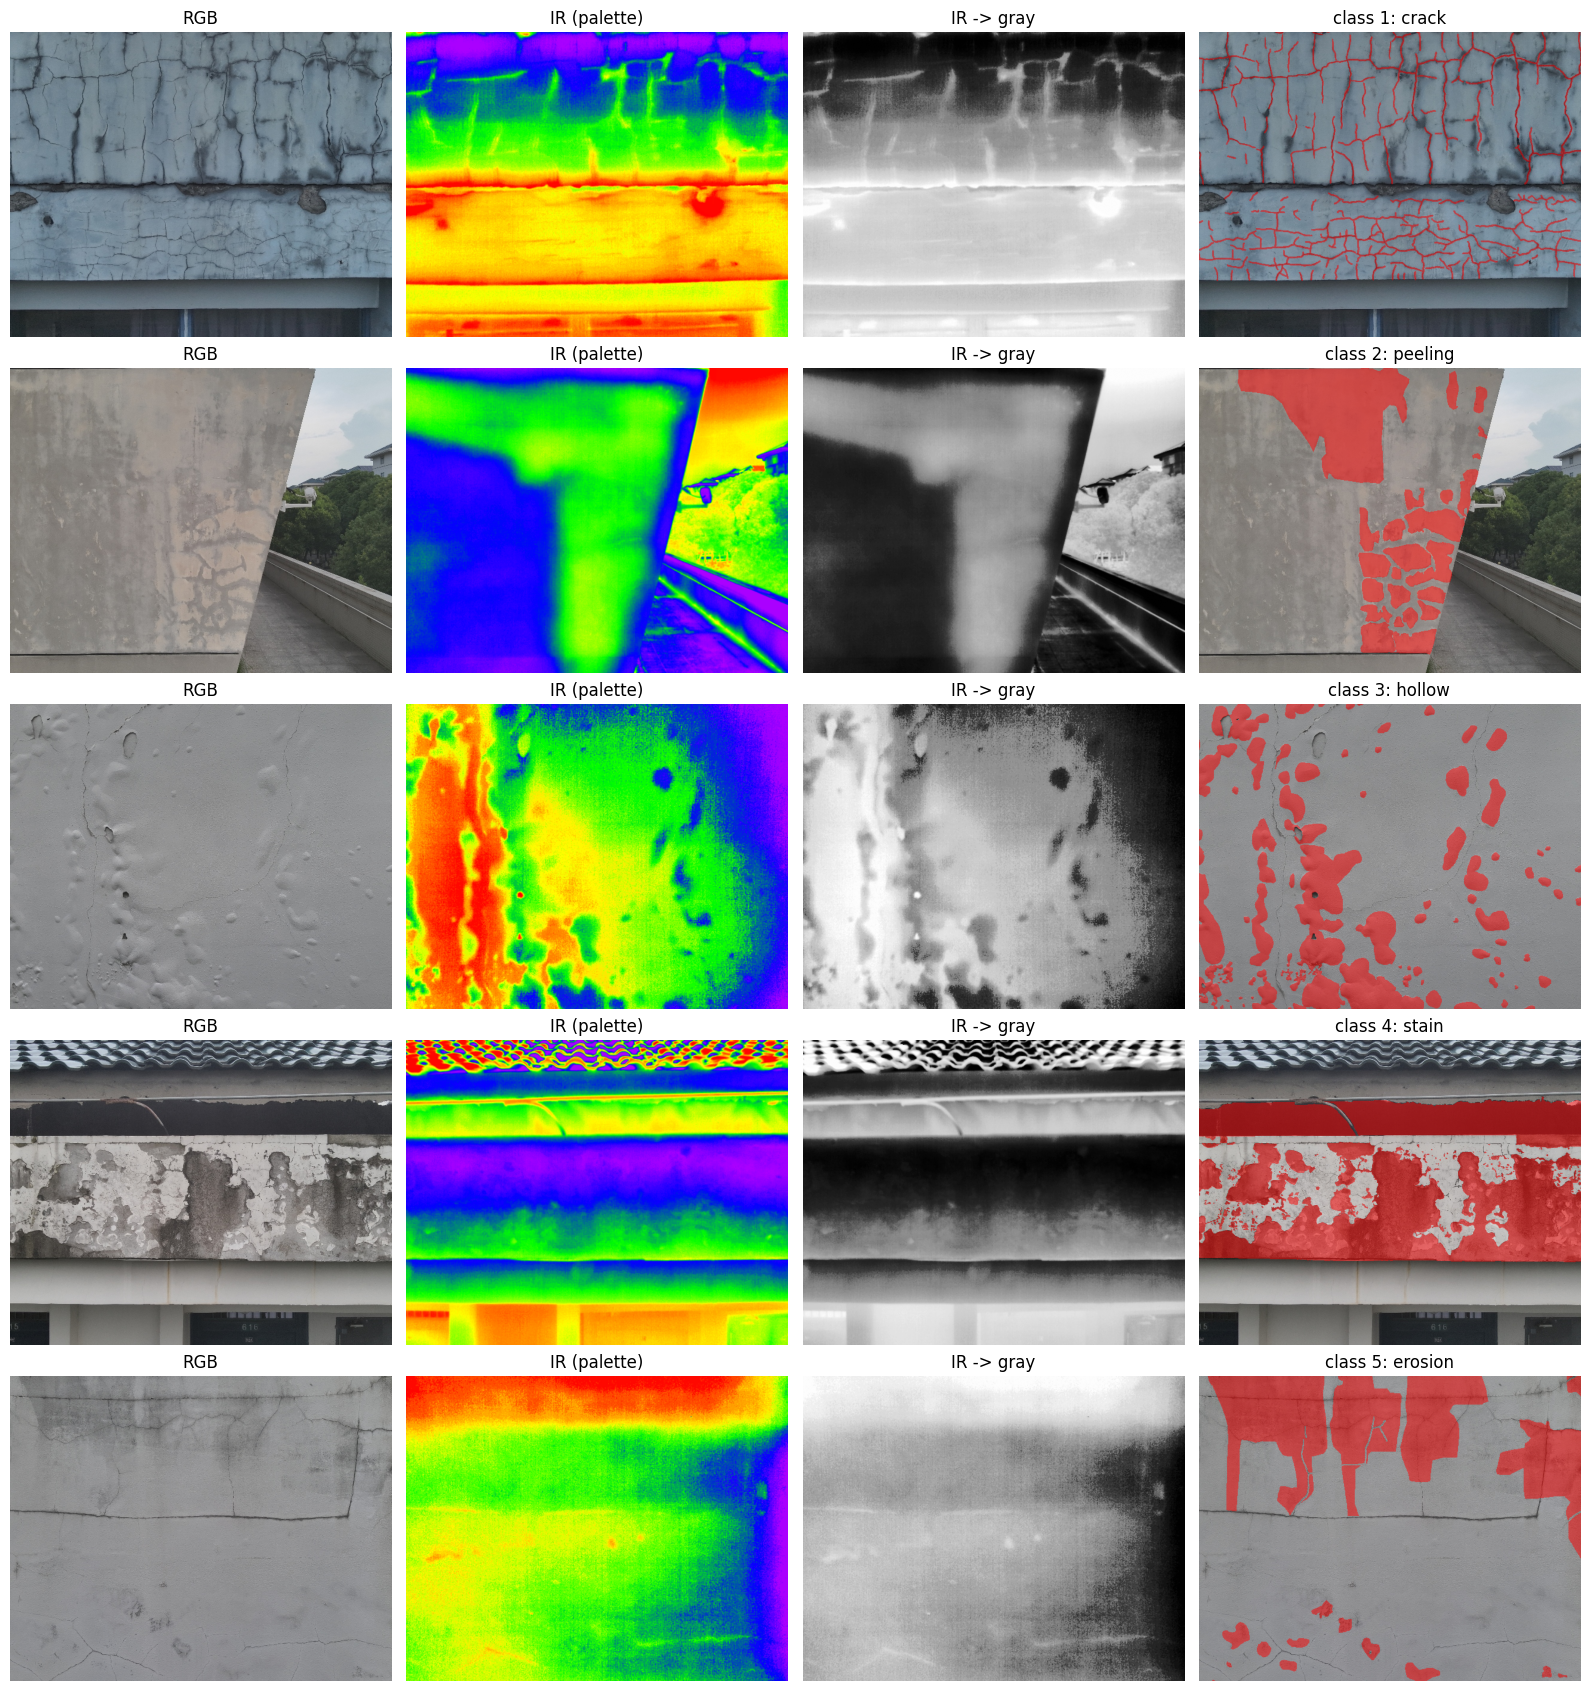

In [5]:
import cv2, numpy as np, matplotlib.pyplot as plt
names = split['train']
fig, ax = plt.subplots(5, 4, figsize=(16, 17))
for k in range(1, 6):
    best = max(names[::4], key=lambda n: (cv2.imread(str(ROOT/'Label'/f'{n}.png'), 0) == k).mean())
    rgb = cv2.imread(str(ROOT/'RGB'/f'{best}.JPG'))[..., ::-1]; irc = cv2.imread(str(ROOT/'IR'/f'{best}.png'))
    lab = cv2.imread(str(ROOT/'Label'/f'{best}.png'), 0)
    ov = rgb.copy(); ov[lab == k] = (255, 0, 0)
    for a, im, t in zip(ax[k-1], [rgb, irc[..., ::-1], F.ir_to_gray(irc), (0.5*rgb + 0.5*ov).astype(np.uint8)],
                        ['RGB', 'IR (palette)', 'IR -> gray', f'class {k}: {F.NAMES[k-1]}']):
        a.imshow(im, cmap='gray' if im.ndim == 2 else None); a.set_title(t); a.axis('off')
plt.tight_layout(); plt.savefig(SAVE_DIR / 'classes.png', dpi=80)

## 3. 학습 전 분석: 바운딩 박스는 실제 손상 면적을 얼마나 과대평가하나? (논문 5.2절)

In [6]:
import pandas as pd
ov = pd.DataFrame(F.box_overestimation(ROOT, split['train'] + split['val'] + split['test']))
ov.to_csv(SAVE_DIR / 'box_vs_mask.csv', index=False); ov

,class,instances,median_box/mask,mean_box/mask
0,crack,19308,4.65,7.68
1,peeling,743,1.70,1.89
2,hollow,6114,1.51,1.69
3,stain,6378,1.69,1.99
4,erosion,3941,1.65,1.88


## 4. 4가지 입력 데이터셋 만들기

In [7]:
DS = WORK / 'datasets'
yamls = F.build_datasets(ROOT, DS, split)
four = cv2.imread(str(DS/'rgbir/images/train'/f"{split['train'][0]}.png"), cv2.IMREAD_UNCHANGED)
print('4채널 shape:', four.shape)

4채널 shape: (512, 640, 4)


## 5. 학습 + 시험 평가

In [8]:
MODES_TO_RUN = F.MODES   # ['rgb', 'ir', 'cbcrir', 'rgbir']
rows, per_class = F.run_experiments(yamls, SAVE_DIR / 'runs', weights=WEIGHTS, epochs=EPOCHS,
                                    imgsz=IMGSZ, batch=BATCH, seed=SEED, modes=MODES_TO_RUN)

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings

===== rgb =====
Ultralytics 8.4.208 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/bfdd/datasets/rgb/data.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=100, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torc

## 6. 결과

,mode,box_P,box_R,box_mAP50,mask_P,mask_R,mask_mAP50,mask_mAP50-95
0,RGB,0.3693,0.2514,0.2144,0.3302,0.2379,0.1859,0.0712
1,IR,0.1085,0.0592,0.0329,0.0631,0.0361,0.0176,0.0053
2,CbCr+IR,0.1688,0.0836,0.0467,0.1279,0.0651,0.0335,0.0105
3,RGB+IR (4ch),0.3894,0.2474,0.2101,0.3457,0.2399,0.1757,0.0693


mode,CbCr+IR,IR,RGB,RGB+IR (4ch)
class,,,,
crack,0.0002,0.0001,0.1018,0.0745
erosion,0.0278,0.0055,0.2241,0.2113
hollow,0.0550,0.0421,0.1211,0.1544
peeling,0.0227,0.0000,0.1685,0.1399
stain,0.0619,0.0401,0.3138,0.2984


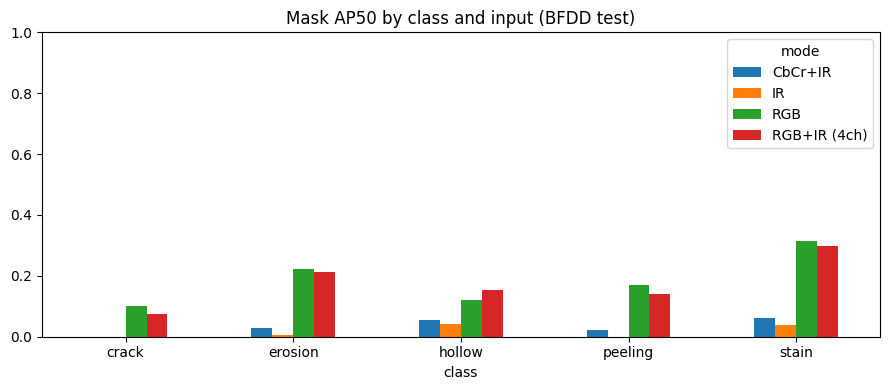

In [9]:
label = {'rgb': 'RGB', 'ir': 'IR', 'cbcrir': 'CbCr+IR', 'rgbir': 'RGB+IR (4ch)'}
res = pd.read_csv(SAVE_DIR/'runs/results_test.csv'); res['mode'] = res['mode'].map(label); display(res)
pc = pd.read_csv(SAVE_DIR/'runs/results_per_class.csv'); pc['mode'] = pc['mode'].map(label)
tab = pc.pivot(index='class', columns='mode', values='mask_AP50'); display(tab)
ax = tab.plot.bar(figsize=(9, 4), rot=0, title='Mask AP50 by class and input (BFDD test)')
ax.set_ylim(0, 1); plt.tight_layout(); plt.savefig(SAVE_DIR / 'per_class.png', dpi=150)

## 7. 추가로 해 본 것
재현만 하고 끝내기는 아쉬워서 두 가지를 더 해 봤다. 둘 다 새로 학습하지 않고, 학습해 둔 RGB+IR 모델에 시험 영상만 바꿔서 넣었다.

**A. RGB와 IR이 어긋나면 어떻게 되나?**

논문에서 RGB–IR 정합 오차가 약 27픽셀(10 mm)인데 박스로 탐지하니까 이 정도면 충분하다고 한 부분이 계속 걸렸다. 정말 괜찮은지 직접 확인하고 싶어서, 시험 영상의 IR 채널만 0, 2, 5, 10, 20, 30픽셀씩 대각선으로 밀어 보고 손상별로 성능이 얼마나 떨어지는지 봤다.

**B. 모델이 실제로 IR을 쓰고 있나?**

RGB+IR이 RGB보다 좋다고 해도, 모델이 IR을 실제로 보고 있는지는 따로 확인해야 한다고 생각했다. 그래서 IR 채널의 공간 정보를 지우고(영상 평균값 하나로 채움) 성능을 다시 쟀다. RGB도 같은 방식으로 지워 봤다. 0이 아니라 평균값으로 채운 건, 0을 넣으면 모델이 처음 보는 값 때문에 성능이 떨어질 수 있어서다. 지웠을 때 많이 떨어지는 손상일수록 그 센서에 기대고 있다고 볼 수 있다.

Ultralytics 8.4.208 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLO11n-seg summary (fused): 114 layers, 2,850,583 parameters, 0 gradients, 9.7 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 3608.1±457.8 MB/s, size: 719.3 KB)
val: Scanning /content/bfdd/ext/shift_00/labels/test... 152 images, 1 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 152/152 378.4it/s 0.4s
val: New cache created: /content/bfdd/ext/shift_00/labels/test.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95)     Mask(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 10/10 2.0it/s 5.0s
                   all        152       2635      0.389      0.247       0.21      0.101      0.346       0.24      0.176     0.0693
Speed: 2.2ms preprocess, 4.8ms inference, 0.0ms loss, 6.5ms postprocess per image
{'ir_shift_px': 0, 'all': 0.1757, 'crack': 0.0745, 'peeling': 0.1399, 'hollow': 0.1544, 'stain': 0.2984, 'erosion': 0.2113}
Ultralytics 8.4.208 🚀 Python-3

,ir_shift_px,all,crack,peeling,hollow,stain,erosion
0,0,0.1757,0.0745,0.1399,0.1544,0.2984,0.2113
1,2,0.1750,0.0779,0.1510,0.1402,0.2980,0.2077
2,5,0.1724,0.0791,0.1475,0.1323,0.2952,0.2077
3,10,0.1721,0.0749,0.1518,0.1295,0.2971,0.2071
4,20,0.1668,0.0731,0.1568,0.1114,0.2849,0.2080
5,30,0.1665,0.0764,0.1443,0.1080,0.2889,0.2148


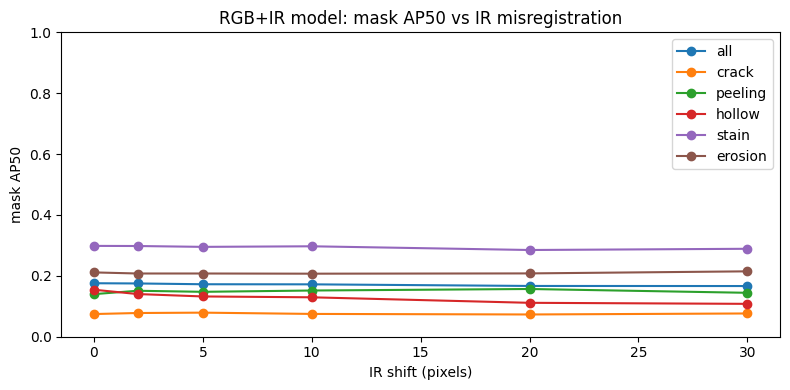

In [10]:
W4 = SAVE_DIR / 'runs/rgbir/weights/best.pt'
EXT = WORK / 'ext'
rob = pd.DataFrame(F.ir_robustness(DS, W4, EXT, shifts=(0, 2, 5, 10, 20, 30), imgsz=IMGSZ, batch=BATCH))
rob.to_csv(SAVE_DIR / 'ir_shift_robustness.csv', index=False); display(rob)
ax = rob.set_index('ir_shift_px').plot(marker='o', figsize=(8, 4), title='RGB+IR model: mask AP50 vs IR misregistration')
ax.set_xlabel('IR shift (pixels)'); ax.set_ylabel('mask AP50'); ax.set_ylim(0, 1)
plt.tight_layout(); plt.savefig(SAVE_DIR / 'ir_shift_robustness.png', dpi=150)

Ultralytics 8.4.208 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLO11n-seg summary (fused): 114 layers, 2,850,583 parameters, 0 gradients, 9.7 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 5021.1±613.3 MB/s, size: 728.9 KB)
val: Scanning /content/bfdd/ext/abl_full/labels/test... 152 images, 1 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 152/152 544.3it/s 0.3s
val: New cache created: /content/bfdd/ext/abl_full/labels/test.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95)     Mask(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 10/10 2.7it/s 3.8s
                   all        152       2635      0.389      0.247       0.21      0.101      0.346       0.24      0.176     0.0693
Speed: 1.7ms preprocess, 4.5ms inference, 0.0ms loss, 4.7ms postprocess per image
{'input': 'full', 'all': 0.1757, 'crack': 0.0745, 'peeling': 0.1399, 'hollow': 0.1544, 'stain': 0.2984, 'erosion': 0.2113}
Ultralytics 8.4.208 🚀 Python-3.

,input,all,crack,peeling,hollow,stain,erosion
0,full,0.1757,0.0745,0.1399,0.1544,0.2984,0.2113
1,IR removed,0.1737,0.0769,0.1670,0.1168,0.3011,0.2066
2,RGB removed,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000


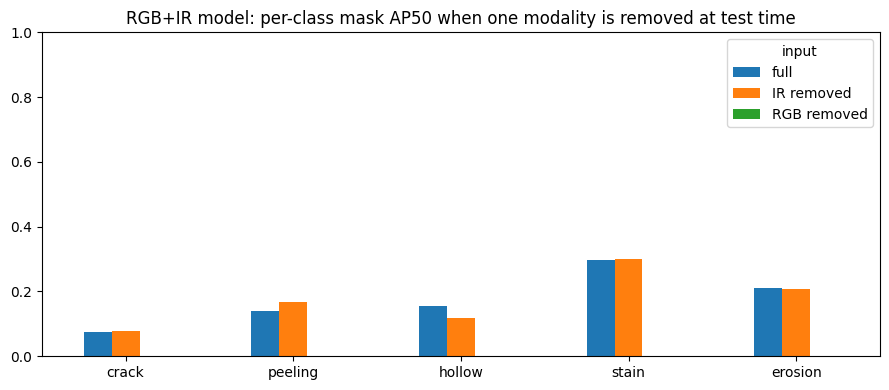

In [11]:
abl = pd.DataFrame(F.channel_ablation(DS, W4, EXT, imgsz=IMGSZ, batch=BATCH))
abl.to_csv(SAVE_DIR / 'modality_ablation.csv', index=False); display(abl)
ax = abl.set_index('input').drop(columns='all').T.plot.bar(rot=0, figsize=(9, 4),
        title='RGB+IR model: per-class mask AP50 when one modality is removed at test time')
ax.set_ylim(0, 1); plt.tight_layout(); plt.savefig(SAVE_DIR / 'modality_ablation.png', dpi=150)